In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, WhiteKernel, ConstantKernel

from scipy.stats import pearsonr

In [9]:

#load cleaned data
pce_data = pd.read_csv("data/pce_data_clean.csv")
bg_data = pd.read_csv("data/bandgap_data_clean.csv")


In [10]:
S = ["Cs", "FA", "MA", "Pb", "Sn", "I", "Br", "Cl"]
layer_cols = ["Architecture", "ETL", "HTL", "Substrate", "Backcontact"]

In [11]:
X = pd.get_dummies(pce_data[S + ["Eg", "Area"] + layer_cols], columns=layer_cols, dtype=int)
y = pce_data["PCE"]

Xb = bg_data[S]
yb = bg_data["Eg"]

print(X.shape, Xb.shape)   # (635, 29) (588, 8)

(635, 29) (588, 8)


In [12]:
#splitting the PCE data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
Xb_train, Xb_test, yb_train, yb_test = train_test_split(Xb, yb, test_size=0.2, random_state=42)

print(len(X_train), "training rows,", len(X_test), "test rows")   # 508, 127
print(len(Xb_train), "training rows,", len(Xb_test), "test rows") # 508, 127

508 training rows, 127 test rows
470 training rows, 118 test rows


In [13]:
#the scoring function for the model
def score(y_true, y_pred):
    r = pearsonr(y_true, y_pred)[0]                  # [0] = the r value ([1] is a p-value)
    rmse = mean_squared_error(y_true, y_pred) ** 0.5  # square root of the mean squared error
    return r, rmse

In [14]:
kernel = ConstantKernel(1.0) * Matern(length_scale=1.0, nu=1.5) + WhiteKernel(noise_level=0.1)

In [15]:
#bandgap model

gp_bg = make_pipeline(
    StandardScaler(),
    GaussianProcessRegressor(kernel=kernel, normalize_y=True,
                             n_restarts_optimizer=3, random_state=42),
)
gp_bg.fit(Xb_train, yb_train)

mean, std = gp_bg.predict(Xb_test, return_std=True)

r, rmse = score(yb_test, mean)
print(f"GP band gap:  r = {r:.2f},  RMSE = {rmse:.3f} eV")   # r = 0.95, RMSE = 0.088 eV
print("Learned kernel:", gp_bg[-1].kernel_)

GP band gap:  r = 0.94,  RMSE = 0.088 eV
Learned kernel: 2.73**2 * Matern(length_scale=6.7, nu=1.5) + WhiteKernel(noise_level=0.0449)


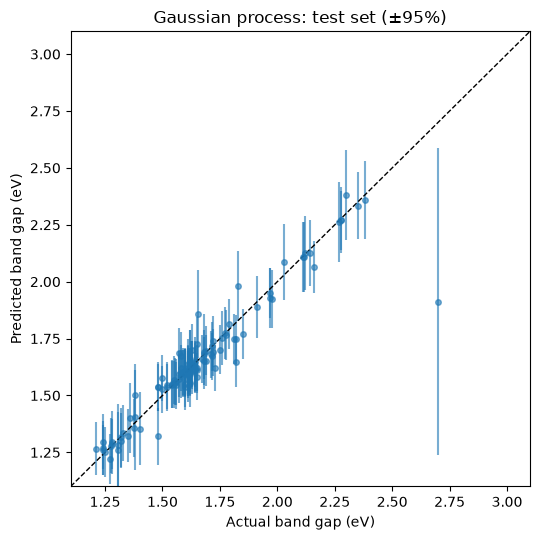

In [16]:
#plotting predictions with error bars

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.errorbar(yb_test, mean, yerr=1.96 * std, fmt="o", ms=4, alpha=0.6, capsize=0)
lims = [1.1, 3.1]
ax.plot(lims, lims, "k--", lw=1)
ax.set(xlim=lims, ylim=lims, xlabel="Actual band gap (eV)",
       ylabel="Predicted band gap (eV)", title="Gaussian process: test set (±95%)")
plt.tight_layout()
plt.show()

In [17]:
#checking how much the true value sits within the error bar

inside = np.abs(yb_test - mean) < 1.96 * std
print(f"True value inside the 95% range: {inside.mean():.0%}")   # 94%

True value inside the 95% range: 94%


In [18]:
#PCE model for GPR

gp_pce = make_pipeline(
    StandardScaler(),
    GaussianProcessRegressor(kernel=kernel, normalize_y=True,
                             n_restarts_optimizer=3, random_state=42),
)
gp_pce.fit(X_train, y_train)

mean_pce, std_pce = gp_pce.predict(X_test, return_std=True)
r, rmse = score(y_test, mean_pce)
print(f"GP PCE:  r = {r:.2f},  RMSE = {rmse:.2f} %")   # r = 0.82, RMSE = 3.06 %

GP PCE:  r = 0.82,  RMSE = 3.06 %


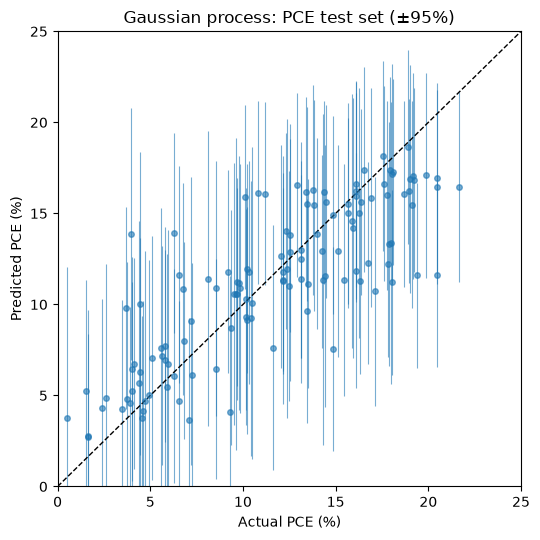

True value inside the 95% range: 91%


In [22]:
#plotting predictions with error bars for PCE model

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.errorbar(y_test, mean_pce, yerr=1.96 * std_pce, fmt="o", ms=4, alpha=0.6, elinewidth=0.8, capsize=0)
lims = [0, 25]
ax.plot(lims, lims, "k--", lw=1)
ax.set(xlim=lims, ylim=lims, xlabel="Actual PCE (%)", ylabel="Predicted PCE (%)",
       title="Gaussian process: PCE test set (±95%)")
plt.tight_layout()
plt.show()

#checking how much the true value sits within the error bar

inside = np.abs(y_test - mean_pce) < 1.96 * std_pce
print(f"True value inside the 95% range: {inside.mean():.0%}")   # 94%